# Do Socioeconomic Factors Predict School Performance?

## Introduction
Standardized test results differ widely from school to school, and these differences are often linked to the communities that schools serve. This project asks a single question: **is school performance, measured by the average ACT score, predicted by socioeconomic factors?** The ACT is a college admissions exam scored from 1 to 36, and a school's average ACT score is a common summary of how its students perform. Knowing how much of the difference in scores is associated with the economic circumstances of a school's community matters for discussions of educational equity and for deciding where schools may need additional support.

The analysis follows the data science methodology: pose the question, collect the data, prepare and explore it, build models, evaluate them, and communicate the conclusions. The data loading, cleaning, joining and imputation steps are in `education_data_preparation.ipynb`, and the exploratory data analysis is in `education_eda.ipynb`. **This notebook covers the modeling and evaluation steps**, starting from the clean data file `education_clean.csv`.

**Response variable:** `average_act`, the average ACT score at the school.

**Socioeconomic predictors** (from EdGap): `median_income` (in dollars), `rate_unemployment`, `percent_college`, `percent_married` and `percent_lunch` (the share of students receiving free or reduced price lunch). The last four are proportions between 0 and 1.

**Added predictor:** `charter` (whether the school is a charter school), from the school information data. It is included to test whether school type is related to ACT scores beyond the socioeconomic factors, and the reasons are given in the section where it is added.

**Plan.**
1. Fit and assess single-input models, starting with median income and then the other four socioeconomic predictors, including quadratic versions.
2. Fit a multiple linear regression model with all five predictors and check how the predictors overlap.
3. Fit a reduced model that keeps only the useful predictors and compare it with the full model.
4. Standardize the predictors so that the coefficients can be compared with each other.
5. Add charter status and test whether it improves the model.
6. Conclude whether socioeconomic factors predict school performance.

## Data sources
- **EdGap data (`EdGap_data.xlsx`)**: 2016 data from [EdGap.org](https://www.edgap.org/) with the average ACT score of each school (SAT scores are converted to ACT equivalents) and socioeconomic measures for the community of the school: median income, unemployment rate, percent of adults with a college education, percent of married families, and percent of students receiving free or reduced price lunch.
- **School information (`ccd_sch_029_1617_w_1a_11212017.csv`)**: the 2016-2017 school-level file of the [NCES Common Core of Data](https://nces.ed.gov/ccd/), which describes every public school in the United States. It supplies the state, zip code, school type, school level and charter status of each school.
- **Clean data (`education_clean.csv`)**: the two sources were cleaned, joined on the school ID and imputed in `education_data_preparation.ipynb`, and the result was exported to this file. It has one row per school, and this notebook reads it in the next section.

# Import libraries
Import libraries for data handling, plotting, modeling, and error metrics.

In [2]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

# Model preprocessing
from sklearn.preprocessing import StandardScaler

# Modeling
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Model metrics and analysis
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Load clean data
Load the clean data set exported by `education_data_preparation.ipynb`. Each row is one high school.

In [3]:
data_folder = '/Users/amruta/coursework_local/DATA_5100/education/data'

df = pd.read_csv(f'{data_folder}/education_clean.csv')

Preview the first rows.

In [4]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No


Each row describes one school. The response `average_act` and the five socioeconomic predictors are the columns used in this notebook. Four predictors are proportions between 0 and 1, while `median_income` is measured in dollars and ranges over tens of thousands. This difference in scale explains why the income coefficient will look tiny and motivates the standardization step at the end. The remaining columns (state, school type, school level, charter) are not used here.

# Modeling

## Single input models
In a single input model, one socioeconomic predictor at a time is used to predict the average ACT score. Starting with median income, each model is fit, summarized, and assessed with plots and error metrics. Polynomial (quadratic) versions are tried to see whether a curved relationship fits better than a straight line.

### Median income

#### Plot the regression line and the scatter plot
Plot median income against average ACT with a fitted line.

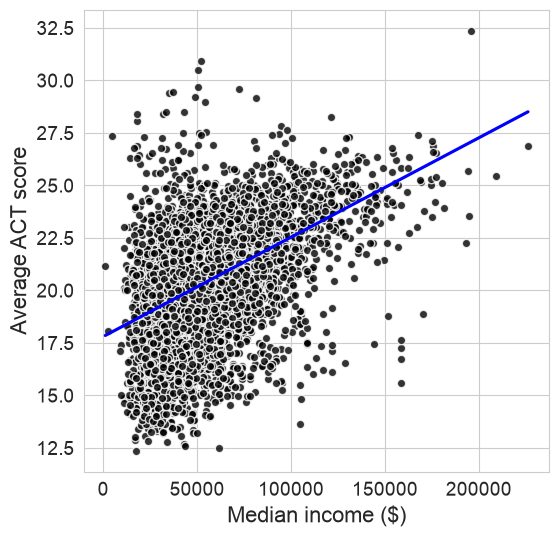

In [5]:
plt.figure(figsize = (6, 6))

sns.regplot(data = df,
           x = 'median_income',
           y = 'average_act',
           color = 'blue',
           ci = False,
           scatter_kws = {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

# Add axis labels
plt.xlabel('Median income ($)', fontsize = 16)
plt.ylabel('Average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

Schools in higher-income communities tend to have higher average ACT scores, so the relationship is positive. The points are widely scattered around the line, which means median income alone gives only a moderate fit. There is also a group of schools with income below about 50,000 dollars whose scores range from about 12 to over 30, so income does not pin down the score.

### Fit the simple linear regression model
Fit `average_act ~ median_income` with OLS; the intercept is added automatically.

In [6]:
model_median_income = smf.ols(formula = 'average_act ~ median_income', data = df).fit()

#### Display the fit summary
Check the coefficients, p-values, and R-squared.

In [7]:
print(model_median_income.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.211
Model:                            OLS   Adj. R-squared:                  0.211
Method:                 Least Squares   F-statistic:                     1934.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:17:34   Log-Likelihood:                -16043.
No. Observations:                7227   AIC:                         3.209e+04
Df Residuals:                    7225   BIC:                         3.210e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        17.8026      0.063    284.794

- **Intercept (17.80):** the predicted average ACT score for a school with median income of 0 dollars. This is outside the realistic income range, so it serves as the baseline of the line rather than a meaningful prediction.
- **Slope (4.73e-05):** each extra dollar of median income is associated with an increase of about 0.0000473 ACT points. The coefficient is tiny only because income is measured in dollars. Per 10,000 dollars the increase is about 0.47 ACT points.
- **Significance:** the p-value for the slope is 0.000 (t = 44.0), and its 95% confidence interval (4.52e-05 to 4.94e-05) does not include zero. The relationship between income and ACT is therefore statistically significant.
- **R-squared (0.211):** median income explains about 21% of the variation in average ACT scores, which is relatively low.
- The warning about a large condition number comes from income being measured in dollars. With a single predictor it is a scaling issue and not a sign of multicollinearity.

#### Numerical assessment of fit accuracy

##### Compute the R-squared
The proportion of variation in ACT explained by the model.

In [8]:
model_median_income.rsquared

np.float64(0.2111864897930108)

##### Compute the predictions
Needed for the error metrics and the residual plot.

In [9]:
predicted_act_median_income = model_median_income.predict()

##### Compute the RMSE
The square root of the mean squared error, in ACT points.

In [10]:
np.sqrt(mean_squared_error(df['average_act'], predicted_act_median_income)).round(3)

np.float64(2.228)

##### Compute the mean absolute error (MAE)
The average absolute prediction error, in ACT points.

In [11]:
mean_absolute_error(df['average_act'], predicted_act_median_income)

1.712938698068855

R-squared is 0.211, which is low. The RMSE is 2.23 and the MAE is 1.71, so the predictions are off by about 1.7 ACT points on average. The RMSE is larger than the MAE because it gives more weight to the occasional large errors. For context, average ACT scores vary across schools with a standard deviation of about 2.5 points (derived from the sum of squares in the model), so an RMSE of 2.23 is only a modest improvement over predicting the overall mean for every school. A higher R-squared and lower RMSE and MAE indicate a better fit, so these numbers describe a weak model.

#### Residual plot
Plot residuals against predicted scores. A patternless cloud means the predictor is used well.

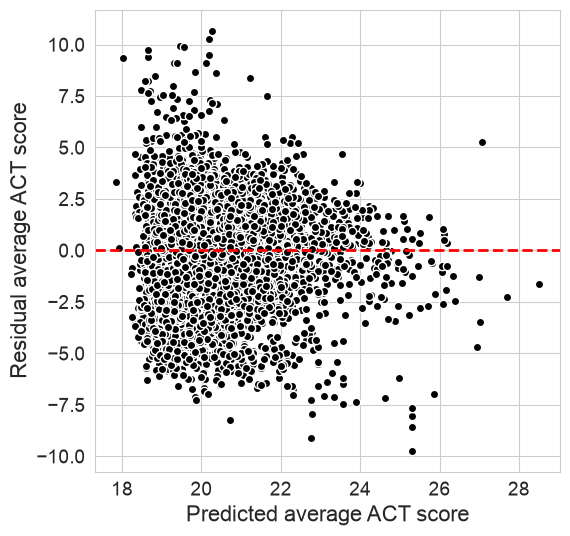

In [12]:
plt.figure(figsize = (6, 6))

plt.plot(predicted_act_median_income, model_median_income.resid, 'ko', mec = 'w')
plt.axhline(0, color = 'r', linestyle = 'dashed', lw = 2)

# Add axis labels
plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

The residuals are scattered around zero, but their spread is not constant. The residuals are widest for the lowest predicted scores (from about -7 to above +10) and narrow for the highest predicted scores. This funnel shape suggests heteroscedasticity (non-constant variance), and there are also some outliers. The linear model may therefore not fully capture the pattern in the data, which motivates trying a more flexible model.

#### Quadratic model: regression curves and scatter plot
Compare the straight line (blue) with a quadratic curve (orange).

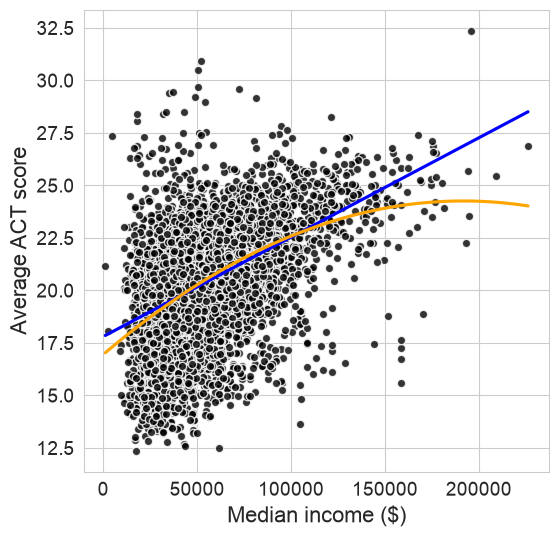

In [13]:
plt.figure(figsize = (6, 6))

sns.regplot(data = df,
           x = 'median_income',
           y = 'average_act',
           color = 'blue',
           ci = False,
           scatter_kws = {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

sns.regplot(data = df,
           x = 'median_income',
           y = 'average_act',
           order = 2, # compute a quadratic regression line
           color = 'orange',
           ci = False,
           scatter = False)

# Add axis labels
plt.xlabel('Median income ($)', fontsize = 16)
plt.ylabel('Average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

The quadratic curve is below the line at the lowest incomes, close to it in the middle, and flattens above about 100,000 dollars, reaching a maximum near 190,000 dollars. This says that higher income is associated with higher scores but with diminishing gains at the top. The two fits stay close over most of the data, so the quadratic is not obviously better.

### Fit a quadratic linear regression model
Add a squared term; `I()` makes the formula treat `median_income**2` as ordinary arithmetic.

In [14]:
model_median_income2 = smf.ols(
    formula = 'average_act ~ median_income + I(median_income**2)', # I() makes the formula treat median_income**2 as plain arithmetic
    data = df).fit()

#### Display the fit summary

In [15]:
print(model_median_income2.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.219
Model:                            OLS   Adj. R-squared:                  0.219
Method:                 Least Squares   F-statistic:                     1013.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:17:35   Log-Likelihood:                -16007.
No. Observations:                7227   AIC:                         3.202e+04
Df Residuals:                    7224   BIC:                         3.204e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                16.94

R-squared rises only from 0.211 to 0.219. The linear coefficient is positive (7.63e-05) and the squared coefficient is negative (-1.99e-10), which gives a curve that rises and then flattens, consistent with the plot. Both terms have p-values of 0.000. The very large condition number (2.27e10) appears because income squared is on an enormous scale. It is a numerical effect of the units and could be reduced by standardizing income.

#### Assess the model significance
Extract the exact p-values.

In [16]:
model_median_income2.pvalues

Intercept                0.000000e+00
median_income            2.631899e-99
I(median_income ** 2)    1.395848e-17
dtype: float64

Both the linear term (p = 2.6e-99) and the squared term (p = 1.4e-17) are far below 0.05, so both are statistically significant. (The intercept p-value of 0 is a numerical underflow and means it is extremely small.)

#### Compare the nested models
An F-test (ANOVA) checks whether the squared term reduces the residual sum of squares more than chance would.

In [17]:
anova_lm(model_median_income, model_median_income2)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7225.0,35865.012794,0.0,NaN,NaN,NaN
1,7224.0,35505.105960,1.0,359.906834,73.227974,1.395848e-17


The quadratic model lowers the residual sum of squares from about 35,865 to 35,505, which is a reduction of only about 1%. The F statistic is 73.2 and the p-value is 1.4e-17, so the improvement is statistically significant. This p-value is identical to the p-value of the squared term because the models differ only by that term. With more than 7,000 schools even a very small improvement can be statistically significant, so statistical significance does not by itself show that the improvement is practically important.

#### Assess the model accuracy
Compare the MAE of the two models.

Mean absolute error of the quadratic model:

In [18]:
mean_absolute_error(df['average_act'], model_median_income2.predict())

1.6972389257635734

Mean absolute error of the linear model:

In [19]:
mean_absolute_error(df['average_act'], model_median_income.predict())

1.712938698068855

The quadratic model has a MAE of 1.697 and the linear model 1.713, so adding the squared term improves the average prediction by only about 0.016 ACT points. This is not practically meaningful. A more complex model is worth using only when it improves accuracy by an amount that matters, or when residuals show clear structure that a simpler model misses. Here the straight line is sufficient.

Median income alone gives a significant but weak prediction of average ACT score (R-squared of about 0.21 and a typical error of about 1.7 points), and a quadratic term adds almost nothing. The next section checks the other four socioeconomic predictors in the same way.

### Other predictors: single input models
Repeat the analysis for the other four predictors, plotting linear (blue) and quadratic (orange) fits.

In [20]:
socioeconomic_predictors = ['rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'percent_lunch']
other_predictors = [predictor for predictor in socioeconomic_predictors if predictor != 'median_income']

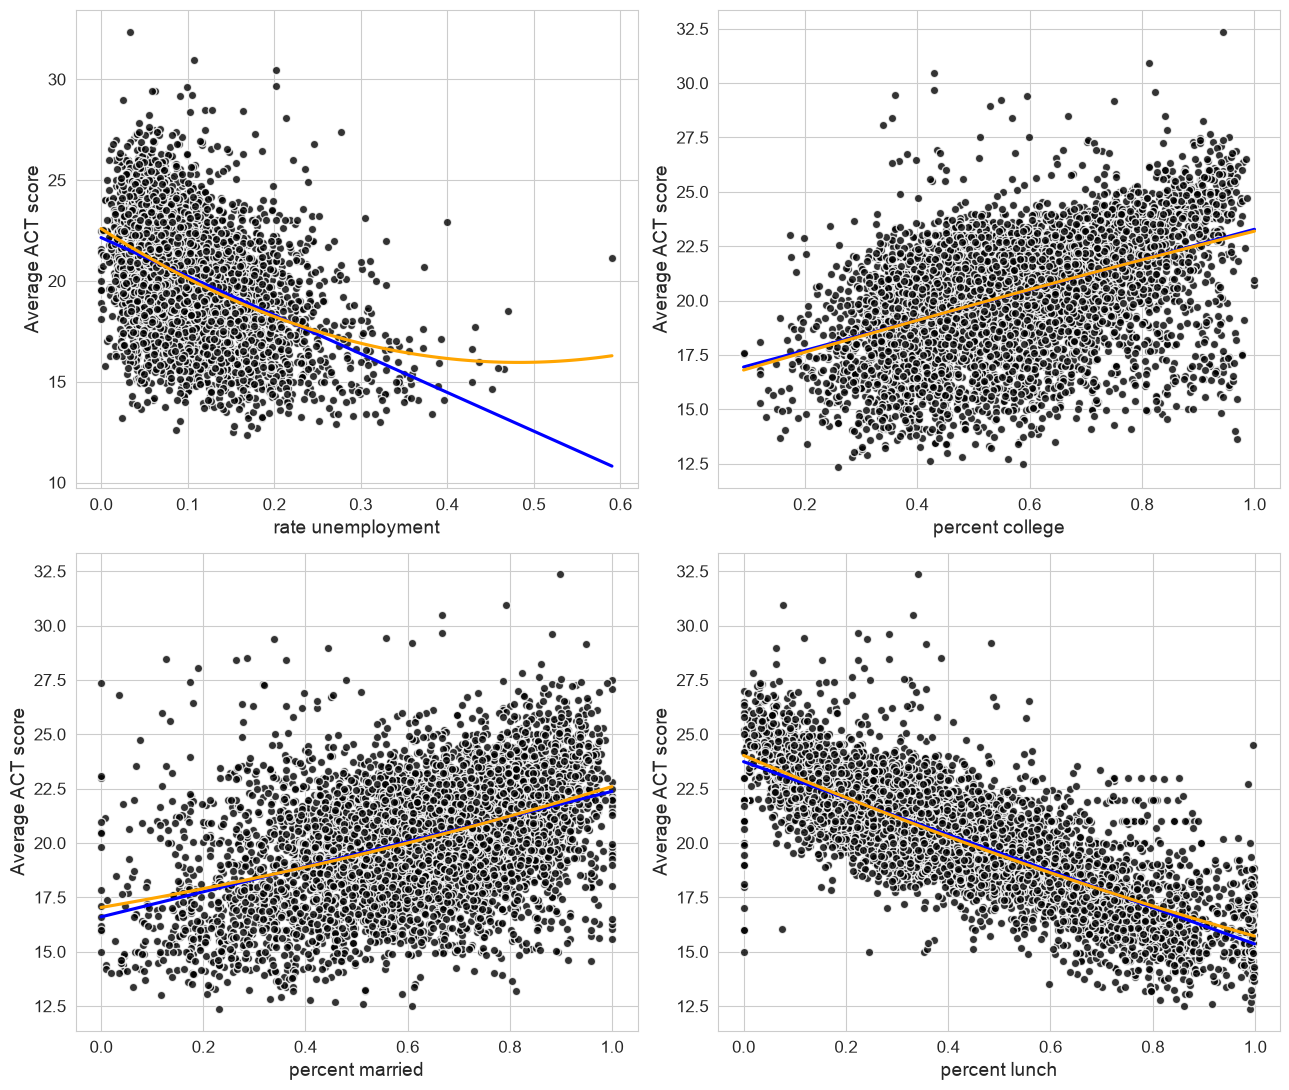

In [21]:
fig, axes = plt.subplots(2, 2, figsize = (13, 11))

for axis, predictor in zip(axes.ravel(), other_predictors):
    sns.regplot(data = df,
                x = predictor,
                y = 'average_act',
                color = 'blue',
                ci = False,
                scatter_kws = {'color': 'black', 'edgecolors': 'white', 'linewidths': 1},
                ax = axis)

    sns.regplot(data = df,
                x = predictor,
                y = 'average_act',
                order = 2,
                color = 'orange',
                ci = False,
                scatter = False,
                ax = axis)

    axis.set_xlabel(predictor.replace('_', ' '), fontsize = 14)
    axis.set_ylabel('Average ACT score', fontsize = 14)
    axis.tick_params(labelsize = 12)

plt.tight_layout()
plt.show()

Each panel shows how one predictor relates to the average ACT score. The slope of the blue line gives the direction of the relationship (an upward line is a positive relationship and a downward line a negative one). The tightness of the points around the line shows its strength, and the orange curve shows whether bending the line changes the picture. The next step puts numbers on these impressions.

#### Compare linear and quadratic models for every predictor
Collect the slope, p-value, R-squared, and MAE for all five predictors in one table.

In [22]:
single_input_results = []

for predictor in socioeconomic_predictors:
    linear_model = smf.ols(formula = f'average_act ~ {predictor}', data = df).fit()
    quadratic_model = smf.ols(formula = f'average_act ~ {predictor} + I({predictor}**2)', data = df).fit()

    single_input_results.append({
        'predictor': predictor,
        'linear slope': linear_model.params[predictor],
        'linear slope p-value': linear_model.pvalues[predictor],
        'linear R-squared': linear_model.rsquared,
        'linear MAE': mean_absolute_error(df['average_act'], linear_model.predict()),
        'quadratic R-squared': quadratic_model.rsquared,
        'quadratic MAE': mean_absolute_error(df['average_act'], quadratic_model.predict()),
        'quadratic term p-value': quadratic_model.pvalues.iloc[-1]
    })

single_input_summary = pd.DataFrame(single_input_results).set_index('predictor')
single_input_summary.style.format('{:.3g}')

,linear slope,linear slope p-value,linear R-squared,linear MAE,quadratic R-squared,quadratic MAE,quadratic term p-value
predictor,,,,,,,
rate_unemployment,-19.2,0,0.188,1.74,0.193,1.74,2.36e-12
percent_college,6.97,0,0.21,1.72,0.21,1.72,0.426
percent_married,5.77,0,0.193,1.74,0.194,1.74,0.00524
median_income,4.73e-05,0,0.211,1.71,0.219,1.7,1.4e-17
percent_lunch,-8.39,0,0.614,1.17,0.616,1.17,4.26e-09


Read the table as follows. The sign of the linear slope gives the direction of the relationship, and the linear R-squared and MAE show how much of the variation in ACT that predictor explains on its own. When the quadratic R-squared and MAE are barely different from the linear ones, a straight line is sufficient, which is what was found for median income (0.211 to 0.219). Because the sample is large, the quadratic term can be statistically significant even when it adds little, so the size of the change in R-squared and MAE matters more than its p-value. Every single-input R-squared in this table is necessarily below the R-squared of the model that uses all five predictors together, which is fit in the next section. The correlation matrix in `education_eda.ipynb` already points to the answer: `percent_lunch` has a correlation of -0.78 with the average ACT score, so its single-input linear R-squared is about 0.61 (R-squared equals the squared correlation), while the other four predictors have correlations of 0.43 to 0.46 in magnitude, which gives R-squared values of about 0.18 to 0.21.

In [23]:
best_predictor = single_input_summary['linear R-squared'].idxmax()
worst_predictor = single_input_summary['linear R-squared'].idxmin()

print(f"Strongest single predictor: {best_predictor} (linear R-squared = {single_input_summary.loc[best_predictor, 'linear R-squared']:.3f}, MAE = {single_input_summary.loc[best_predictor, 'linear MAE']:.3f})")
print(f"Weakest single predictor: {worst_predictor} (linear R-squared = {single_input_summary.loc[worst_predictor, 'linear R-squared']:.3f}, MAE = {single_input_summary.loc[worst_predictor, 'linear MAE']:.3f})")

Strongest single predictor: percent_lunch (linear R-squared = 0.614, MAE = 1.169)
Weakest single predictor: rate_unemployment (linear R-squared = 0.188, MAE = 1.742)


The printed lines identify which socioeconomic variable explains the most and the least ACT variation by itself. Predictors with a low single-input R-squared may still help in a model with other predictors, and predictors that look useful alone may overlap with each other. The multiple regression in the next section addresses both points.

## Multiple linear regression
Fit one model with all five predictors using OLS.

In [24]:
model_full = smf.ols(
    formula = 'average_act ~ rate_unemployment + percent_college + percent_married + median_income + percent_lunch ',
    data = df).fit()

### Print the summary

In [25]:
print(model_full.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     2438.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:17:38   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.667e+04
Df Residuals:                    7221   BIC:                         2.671e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6972      0.13

- **Fit:** R-squared is 0.628, far above the 0.211 of the median income model, so the five predictors together explain about 63% of the variation in average ACT scores.
- **Significant predictors:** `percent_lunch` (-7.60, t = -78.5), `percent_college` (+1.74) and `rate_unemployment` (-2.27) all have p-values of 0.000. Holding the other predictors fixed, a 10 percentage point increase in the share of students on free or reduced lunch is associated with about 0.76 fewer ACT points. A 10 point increase in the share of college-educated adults is associated with about 0.17 more points, and a 10 point increase in unemployment with about 0.23 fewer points.
- **Predictors that lose significance:** `percent_married` (p = 0.577) and `median_income` (p = 0.920) are not statistically significant. The coefficient on median income is essentially zero (-1.2e-07) and its confidence interval contains zero. Income was strongly significant and positive on its own, so this does not mean income is unrelated to ACT. It means income adds little once the other variables are in the model, because the information it carries is already captured by them.
- The large condition number warning (1.34e6) is checked in the next two cells.

### Check for multicollinearity
Correlated predictors share information, which inflates standard errors. Check the correlation matrix and each predictor's variance inflation factor (VIF).

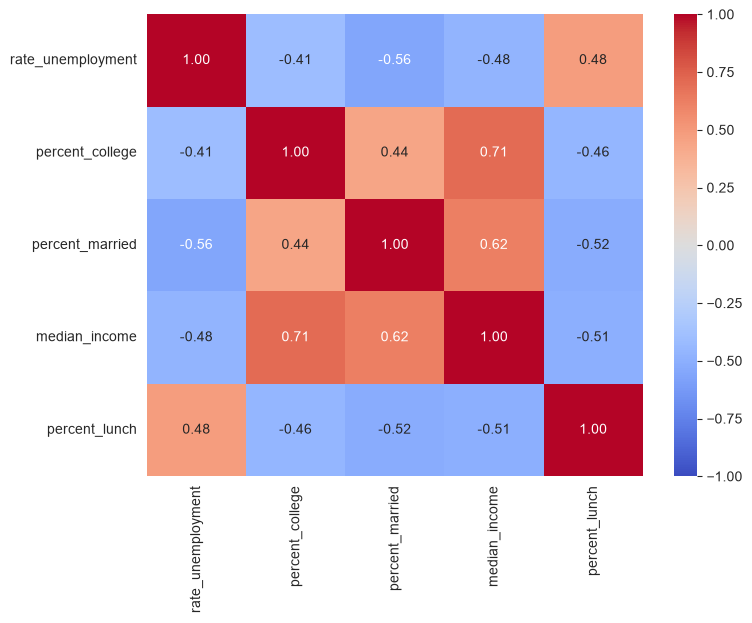

In [26]:
predictor_correlations = df[socioeconomic_predictors].corr()

plt.figure(figsize = (8, 6))
sns.heatmap(predictor_correlations, annot = True, fmt = '.2f', cmap = 'coolwarm', vmin = -1, vmax = 1)
plt.show()

Values near +1 or -1 mean that two predictors move together, and values near 0 mean they are nearly unrelated. These variables all describe the socioeconomic circumstances of a school's community, so it is expected that several of them are correlated. Pairs with a large absolute correlation carry overlapping information, so they are the candidates for dropping one of the pair. In this data the strongest overlaps are between `percent_college` and `median_income` (0.71) and between `median_income` and `percent_married` (0.62), as also seen in the exploratory analysis.

In [27]:
predictors_with_constant = sm.add_constant(df[socioeconomic_predictors])

variance_inflation_factors = pd.Series(
    [variance_inflation_factor(predictors_with_constant.values, column_index)
     for column_index in range(1, predictors_with_constant.shape[1])],
    index = socioeconomic_predictors)

variance_inflation_factors.round(2)

rate_unemployment    1.61
percent_college      2.08
percent_married      2.02
median_income        2.68
percent_lunch        1.59
dtype: float64

A VIF of 1 means that a predictor is unrelated to the others. Values above about 5 are commonly taken as a sign of problematic overlap, and above 10 as serious. The predictors with the highest VIFs are the ones whose information is most duplicated by the others, which is the situation that makes `median_income` and `percent_married` lose significance in the full model. The condition number in the model summary also reflects the very different scales of the predictors (dollars versus proportions), which is why VIF is a cleaner measure of overlap.

### Residual plot
Check the residuals for remaining structure.

In [28]:
predicted_act_full = model_full.predict()

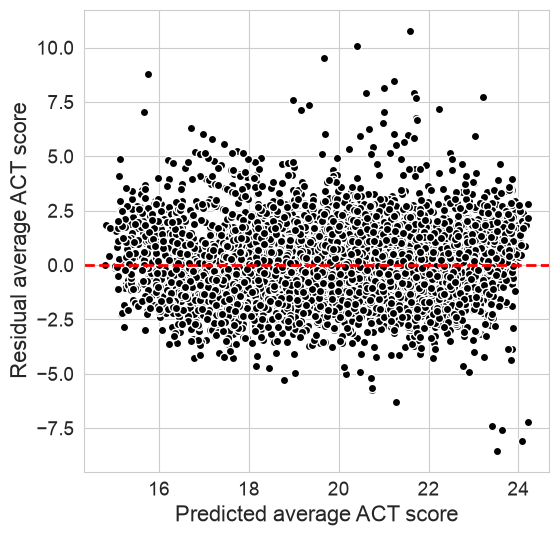

In [29]:
plt.figure(figsize = (6, 6))

plt.plot(predicted_act_full, model_full.resid, 'ko', mec = 'w')
plt.axhline(0, color = 'r', linestyle = 'dashed', lw = 2)

# Add axis labels
plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

Unlike the median income model, the residuals of the full model form a roughly even band around zero across all predicted values, with no curve and no funnel shape. A few outliers remain (up to about +10 and down to about -8.5). The absence of structure suggests that transforming these predictors is unlikely to improve the model much.

### Compute the mean absolute error
Compare with 1.71 for median income alone.

In [30]:
mean_absolute_error(df['average_act'], model_full.predict())

1.1453304788884031

The full model has a MAE of 1.145, down from 1.713 for median income alone. The typical prediction error falls by about a third, which is a practically meaningful improvement.

### Summary
1. The multiple linear regression model with all five socioeconomic predictors has an R-squared of 0.628 and predicts average ACT scores to within about 1.1 points on average (MAE = 1.145), much better than any single predictor used above.
2. The residual plot shows no structure, so transforming the predictors is unlikely to help much.
3. Not all predictors have significant coefficients: `percent_married` and `median_income` do not, because they overlap with the other predictors.
4. A smaller set of these predictors may be enough. Other variables from the data set, such as state or charter status, could be added to improve performance further.

## Fit a reduced model
Drop the predictors that are not significant (p > 0.05) and overlap with the others: `percent_married` and `median_income`.

In [31]:
model_reduced = smf.ols(
    formula = 'average_act ~ rate_unemployment + percent_college + percent_lunch',
    data = df).fit()

### Print the summary

In [32]:
print(model_reduced.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     4063.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:17:38   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7223   BIC:                         2.669e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6400      0.10

All three predictors are statistically significant with p-values of 0.000. Their coefficients are almost unchanged from the full model (`rate_unemployment` -2.17 versus -2.27, `percent_college` 1.71 versus 1.74, `percent_lunch` -7.59 versus -7.60), and R-squared is still 0.628. The condition number falls from 1.34e6 to 25.9, mostly because median income and its dollar scale are gone.

### Residual plot
Check that dropping predictors added no structure.

In [33]:
predicted_act_reduced = model_reduced.predict()

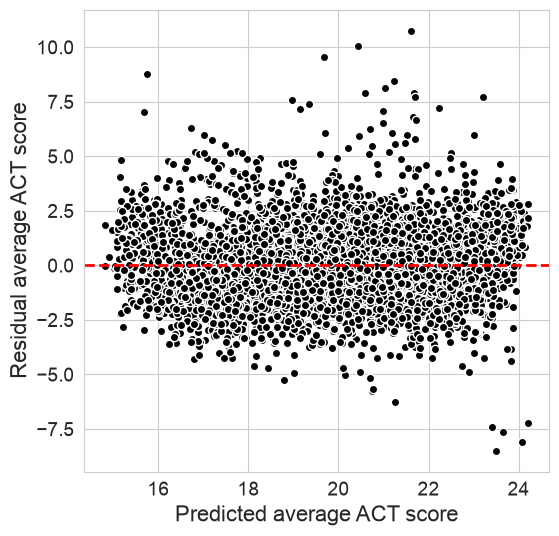

In [34]:
plt.figure(figsize = (6, 6))

plt.plot(predicted_act_reduced, model_reduced.resid, 'ko', mec = 'w')
plt.axhline(0, color = 'r', linestyle = 'dashed', lw = 2)

# Add axis labels
plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

The residual plot of the reduced model looks the same as that of the full model: an even band around zero with no curve or funnel, and the same few outliers. Dropping the two predictors did not introduce any pattern.

### Compute the mean absolute error

In [35]:
mean_absolute_error(df['average_act'], model_reduced.predict())

1.1454832950346379

The reduced model has a MAE of 1.1455, essentially the same as the full model. The next table puts the two models side by side.

### Compare the accuracy of the full and reduced models

In [36]:
mae_full = mean_absolute_error(df['average_act'], model_full.predict())
mae_reduced = mean_absolute_error(df['average_act'], model_reduced.predict())

r2_full = model_full.rsquared
r2_reduced = model_reduced.rsquared

pd.DataFrame({'Mean Absolute Error': [mae_full, mae_reduced],
             'R-squared': [r2_full, r2_reduced]},
            index = ['full model', 'reduced model']).round(4)

,Mean Absolute Error,R-squared
full model,1.1453,0.6280
reduced model,1.1455,0.6279


The MAE (1.1453 versus 1.1455) and R-squared (0.6280 versus 0.6279) are practically identical. The two dropped predictors did not contribute anything measurable to the predictions. A formal test follows.

### ANOVA: full vs reduced model
Test whether the two dropped predictors together improve the fit.

In [37]:
anova_lm(model_reduced, model_full)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7223.0,16916.619167,0.0,NaN,NaN,NaN
1,7221.0,16915.612457,2.0,1.006711,0.214874,0.806648


The F statistic is 0.215 and the p-value is 0.807, which is far above 0.05. The full model does not fit significantly better than the reduced model, so there is no evidence that `percent_married` and `median_income` add anything. When performance is equivalent, the simpler model is preferred: it is easier to explain, less affected by overlapping predictors, and less likely to be overfit.

### Summary
1. The model predicting average ACT score from `rate_unemployment`, `percent_college` and `percent_lunch` is not significantly different from the model with all five socioeconomic variables (F-test p = 0.807), and it has the same R-squared (0.628) and MAE (about 1.145).
2. Predictors were removed because their coefficients were not significant and they overlap with the other predictors, and the reduced model is preferred because it is simpler with the same accuracy.
3. The relative importance of each remaining predictor has not been determined yet, because the coefficients are in different units. This is addressed by standardizing the predictors.

## Scaling
Coefficients are in different units, so they cannot be compared directly. Standardizing the predictors to mean 0 and standard deviation 1 puts them on one scale.

### Standardize the predictors
List the reduced model's predictors.

In [38]:
predictor_variables = ['rate_unemployment', 'percent_college', 'percent_lunch']

Name the scaled columns with a suffix.

In [39]:
# create a list of names of these scaled columns
scaled_columns = [var + '_normalized' for var in predictor_variables]
print(scaled_columns)

['rate_unemployment_normalized', 'percent_college_normalized', 'percent_lunch_normalized']


`StandardScaler` learns each predictor's mean and standard deviation.

In [40]:
# standardize/normalize
scaler = StandardScaler().fit(df[predictor_variables])

Apply the scaling and add the new columns.

In [41]:
df[scaled_columns] = scaler.transform(df[predictor_variables])

### Check the scaled data
Means should be 0 and standard deviations 1.

In [42]:
df[scaled_columns].agg(['mean', 'std']).round(3)

,rate_unemployment_normalized,percent_college_normalized,percent_lunch_normalized
mean,-0.0,-0.0,0.0
std,1.0,1.0,1.0


The means round to 0 and the standard deviations to 1 for all three scaled columns, so the standardization worked.

### Fit the model with standardized predictors

In [43]:
model_normalized = smf.ols(
    formula = 'average_act ~ rate_unemployment_normalized + percent_college_normalized + percent_lunch_normalized',
    data = df).fit()

### Print the summary
Compare with the unscaled reduced model.

In [44]:
print(model_normalized.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     4063.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:17:39   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7223   BIC:                         2.669e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

- **What stays the same:** R-squared (0.628), the F statistic, and the t statistics and p-values of all three predictors (-5.801, 13.504, -81.992) are identical to the unscaled reduced model. The fit does not change because standardizing is only a rescaling of each predictor.
- **What changes:** the coefficients and the intercept, since they are now in standard deviation units. The intercept (20.30) is now the predicted ACT score for a school with average values on all three predictors, which is the mean average ACT score. The condition number drops from 25.9 to 1.93, because the predictors are now on a common scale.
- **Interpretation:** holding the other predictors fixed, a one standard deviation increase in `percent_lunch` is associated with a 1.78 point decrease in predicted ACT. A one standard deviation increase in `percent_college` is associated with a 0.28 point increase and one in `rate_unemployment` with a 0.12 point decrease.

### Compare the accuracy of the normalized and reduced models

In [45]:
mae_normalized = mean_absolute_error(df['average_act'], model_normalized.predict())
mae_reduced = mean_absolute_error(df['average_act'], model_reduced.predict())

r2_normalized = model_normalized.rsquared
r2_reduced = model_reduced.rsquared

pd.DataFrame({'Mean Absolute Error': [mae_normalized, mae_reduced],
             'R-squared': [r2_normalized, r2_reduced]},
            index = ['normalized model', 'reduced model']).round(4)

,Mean Absolute Error,R-squared
normalized model,1.1455,0.6279
reduced model,1.1455,0.6279


The MAE (1.1455) and R-squared (0.6279) are identical for the two models. Standardizing the predictors is a linear transformation, so the fitted values and residuals are exactly the same. Only the scale of the coefficients changes, which makes them comparable with each other.

### Summary
1. Standardizing the predictors does not change the R-squared, MAE, or significance of the model. It only changes the units of the coefficients so that they can be compared.
2. The percent of students at a school receiving free or reduced price lunch (`percent_lunch`) is by far the strongest predictor in this analysis. Its standardized coefficient (-1.78) is about 6 times larger in magnitude than that of `percent_college` (0.28) and about 14 times larger than that of `rate_unemployment` (-0.12). A one standard deviation increase in the share of students on free or reduced lunch is associated with a drop of about 1.8 points in the predicted average ACT score, holding the other predictors fixed.
3. These coefficients describe associations in this data set and not causal effects, and each one is conditional on the other predictors being in the model.

## Adding a predictor: charter status
**Motivation.** The socioeconomic variables describe the community around a school, but not the kind of school. Charter schools are publicly funded but run with more independence, and many enroll students by application or lottery. Their students may therefore differ from the surrounding community in ways that the EdGap variables do not capture, and the school's structure itself may relate to test results. Charter status is already in the clean data (as `Yes`, `No`, or `Not applicable`), so it can be tested directly: does knowing whether a school is a charter improve the prediction of its ACT score once the socioeconomic predictors are in the model?

First, count the schools in each group and compare their average ACT scores. The comparison that follows uses only the schools labeled `Yes` or `No`, because schools labeled `Not applicable` are neither charter nor non-charter schools. and compare their average ACT scores.

In [46]:
print(df['charter'].value_counts(dropna = False))

df_charter_comparison = df[df['charter'].isin(['Yes', 'No'])]

df_charter_comparison.groupby('charter')['average_act'].agg(['count', 'mean', 'median', 'std']).round(2)

charter
No                6858
Not applicable     199
Yes                170
Name: count, dtype: int64


,count,mean,median,std
charter,,,,
No,6858,20.36,20.60,2.50
Yes,170,19.02,18.89,3.14


The table shows how many charter and non-charter schools there are and how their average ACT scores compare. A large difference in group sizes limits how precisely the smaller group can be estimated, and the gap between the group means is the raw difference that the model will then adjust for the socioeconomic predictors.

Compare the distributions of average ACT scores for the two groups with a box plot.

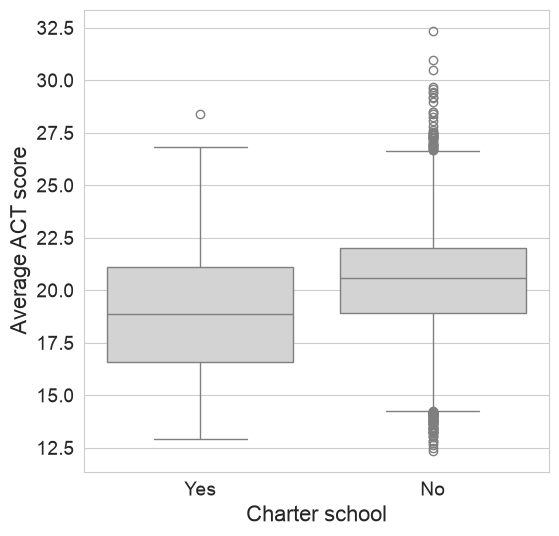

In [47]:
plt.figure(figsize = (6, 6))
sns.boxplot(data = df_charter_comparison, x = 'charter', y = 'average_act', color = 'lightgray')
plt.xlabel('Charter school', fontsize = 16)
plt.ylabel('Average ACT score', fontsize = 16)
plt.tick_params(labelsize = 14)
plt.show()

The box plot shows the median, the middle half of the scores and the outliers of each group. Overlapping boxes mean that charter status separates the scores only partly, and any difference seen here could also come from differences in the communities that the two types of school serve, which the model below adjusts for.

### Fit the reduced model with charter status added
Fit the reduced model with and without charter status on the same schools (those labeled `Yes` or `No`), so that the two models can be compared fairly. Add `C(charter)` to the reduced model formula. `C()` tells statsmodels to treat `charter` as a category, which creates a 0/1 indicator for charter schools (`No` is the reference group). Its coefficient is the difference in predicted ACT between charter and non-charter schools with the same values of the socioeconomic predictors.

In [48]:
model_reduced_charter_schools = smf.ols(formula = 'average_act ~ rate_unemployment + percent_college + percent_lunch',
                                        data = df_charter_comparison).fit()

model_with_charter = smf.ols(formula = 'average_act ~ rate_unemployment + percent_college + percent_lunch + C(charter)',
                             data = df_charter_comparison).fit()

### Print the summary
Check the charter coefficient and whether the socioeconomic coefficients change.

In [49]:
print(model_with_charter.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     2961.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:17:39   Log-Likelihood:                -13001.
No. Observations:                7028   AIC:                         2.601e+04
Df Residuals:                    7023   BIC:                         2.605e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6874      0.10

Look at three things in this summary: the coefficient on `C(charter)[T.Yes]` (its sign gives the direction of the charter difference and its size is in ACT points), its p-value (whether the difference is statistically significant), and whether the coefficients of the three socioeconomic predictors stay close to their values in the reduced model. Stable socioeconomic coefficients mean that charter status is adding information of its own and is not just repeating them.

### Test whether charter status improves the model
The reduced model is nested in the model with charter, so an F-test can check whether adding charter status reduces the residual sum of squares by more than chance.

In [50]:
anova_lm(model_reduced_charter_schools, model_with_charter)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7024.0,16644.481603,0.0,NaN,NaN,NaN
1,7023.0,16639.270660,1.0,5.210944,2.199403,0.138109


A small p-value means that charter status adds statistically significant explanatory power beyond the three socioeconomic predictors, and a large p-value means it does not. With thousands of schools, even a small improvement can be significant, so the practical size of the change is checked next.

Summarize the effect of charter status, and the change in R-squared and mean absolute error, in words.

In [51]:
charter_term = 'C(charter)[T.Yes]'
charter_effect = model_with_charter.params[charter_term]
charter_p_value = model_with_charter.pvalues[charter_term]
direction = 'higher' if charter_effect > 0 else 'lower'

print(f"Holding the socioeconomic predictors fixed, charter schools score {abs(charter_effect):.2f} ACT points {direction} on average than non-charter schools (p = {charter_p_value:.3g}).")
print(f"R-squared: {model_reduced_charter_schools.rsquared:.4f} (without charter) -> {model_with_charter.rsquared:.4f} (with charter)")
print(f"MAE: {model_reduced_charter_schools.resid.abs().mean():.4f} (without charter) -> {model_with_charter.resid.abs().mean():.4f} (with charter)")

Holding the socioeconomic predictors fixed, charter schools score 0.18 ACT points lower on average than non-charter schools (p = 0.138).
R-squared: 0.6276 (without charter) -> 0.6277 (with charter)
MAE: 1.1525 (without charter) -> 1.1525 (with charter)


The printed lines give the size of the charter difference after adjusting for the socioeconomic factors, and how much the fit improves. Compare these changes with the improvement the socioeconomic predictors provided: the reduced model lowered the MAE from about 1.71 ACT points (median income alone) to 1.15. If charter status changes R-squared and MAE only slightly, it is not a practically useful predictor even if its p-value is small, and the socioeconomic factors remain the main explanation.

## Conclusion
**Do socioeconomic factors predict school performance? Yes, to a substantial but incomplete degree.**

- **Each factor matters on its own, but weakly.** Median income alone explains about 21% of the variation in average ACT scores (MAE of 1.71 points), and a quadratic term adds almost nothing. The single-input table compares the other predictors, and `percent_lunch` is by far the strongest of them: its correlation of -0.78 with ACT gives a single-input R-squared of about 0.61, which is already close to the 0.628 of all five predictors together.
- **Together they predict much better.** The multiple regression with all five socioeconomic predictors has an R-squared of 0.628 and predicts a school's average ACT score to within about 1.1 points on average.
- **Three predictors are enough.** `percent_married` and `median_income` lose significance once the other predictors are in the model, because they overlap with them, and dropping them changes neither R-squared nor MAE (F-test p = 0.807). The reduced model with `percent_lunch`, `percent_college` and `rate_unemployment` is preferred because it is simpler with the same accuracy.
- **The share of students on free or reduced price lunch is the strongest predictor.** Its standardized coefficient (-1.78) is about 6 times larger in magnitude than that of `percent_college` (0.28) and about 14 times larger than that of `rate_unemployment` (-0.12).
- **Charter status (added predictor).** The previous section reports the charter difference after adjusting for the socioeconomic factors, and whether it improves the model beyond them.

**Limitations.** About 37% of the variation in ACT scores is not explained by these factors, so socioeconomic variables are strongly related to performance but do not determine it. The coefficients show associations and not causes. The data are school averages with community-level measures, so the results describe schools and not individual students. Other factors that are not in the data, such as school funding, teacher experience, and how many students take the ACT in each state, could also matter. Natural next steps are to add state or school level to the model and to test whether the relationships differ between groups of schools.